# Bike Demand Forecasting: experiment review

Forecast the next day's total bike rentals using historical demand and known calendar information. This models an operational planning question: how much demand should a bike-sharing operator prepare for tomorrow after today's demand is observed?

This notebook inspects the committed experiment. Run `python -m bike_forecast train` from the repository root to regenerate the evidence. Raw datasets and local artifacts are not embedded here.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / "reports/metrics.json").is_file():
    root = root.parent
report = json.loads((root / "reports/metrics.json").read_text())
print("Selected model:", report["selected"])
print("Split:", report["split"])
print("Recorded Python:", report["provenance"]["python"])

Selected model: scaled_ridge
Split: {'train': 583, 'test': 120, 'test_start': '2012-09-03'}
Recorded Python: 3.11.14


## Compare held-out performance

Lower MAE/RMSE/log loss is better; higher F1, accuracy, recall and NDCG is better. The selected model was chosen before examining test outcomes.

In [2]:
comparison = pd.DataFrame(report["test"]).T
display(comparison)

,mae,rmse,r2
seasonal_naive,1342.266667,1911.182718,0.063970
scaled_ridge,931.606203,1298.989397,0.567589
hist_gradient_boosting,1382.293325,1878.049763,0.096143


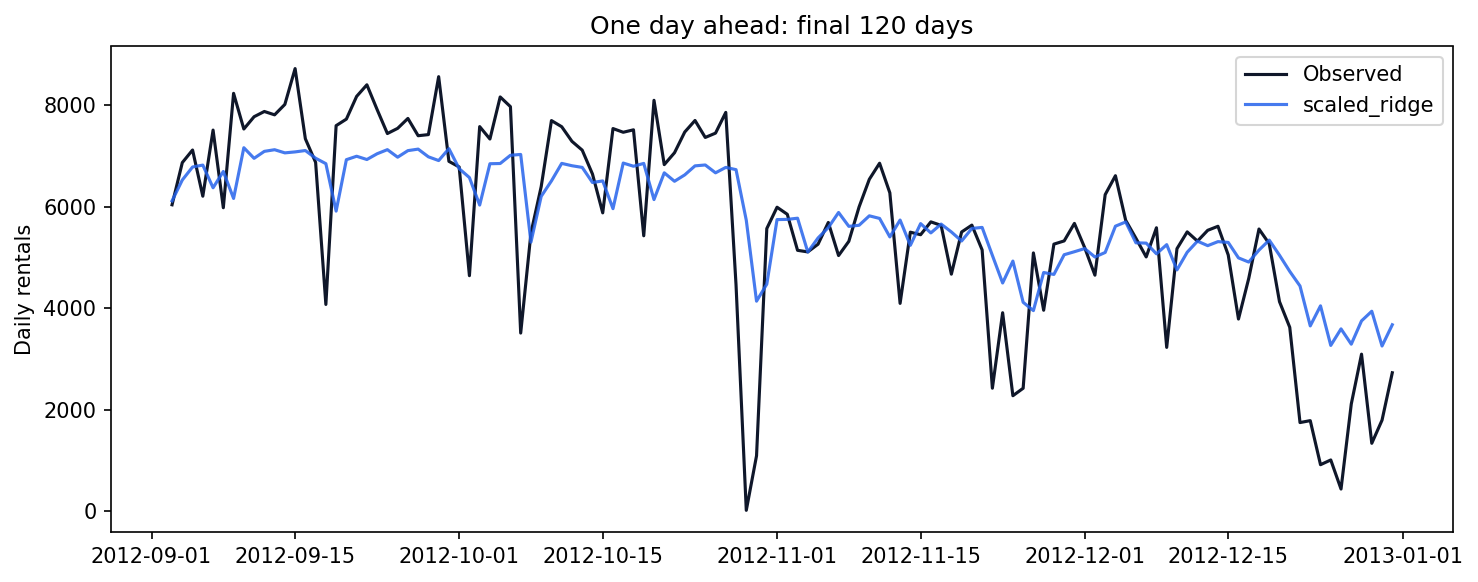

In [3]:
display(Image(filename=str(root / "reports/evaluation.png")))

## What the measurements mean

Ridge wins the backtests and reduces test MAE from 1,342 to 932 rentals/day versus the seven-day baseline. The boosted trees generalize worse in this setup. This is a sequence of one-day-ahead predictions with actual past counts, not a 120-day forecast made at one origin. The difficult late-2012 period remains visible in the chart.

## Where they stop

Only two years from one city are available. Growth, unusual weather, closures and holidays create distribution changes. No weather-forecast archive is used. Linear trend extrapolation can become implausible far outside the training period; the sample 2013 date demonstrates the interface, not present-day demand. A multi-day recursive forecast requires a different evaluation design.